# 04 · Segment-level price and demand analysis

## Purpose

This notebook examines how advertised price relates to the demand proxy within the five final Airbnb listing segments.

The analysis uses the baseline segmentation and focuses on listings for which the demand proxy is considered reliable. Price and demand were not used to create the clusters, so they can now be compared across the resulting market segments.

The aim is to identify segments where demand appears more or less sensitive to advertised price and to highlight the strongest pricing opportunity signals. These relationships are observational and should not be interpreted as causal price effects or optimal pricing recommendations.

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from scipy.stats import spearmanr

## 2. Configuration

In [2]:
RANDOM_SEED = 42
DEMAND_WINSOR_QUANTILE = 0.99
PRICE_BANDS = 4

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airbnb_cleaned_features.csv"
BASELINE_LABELS_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "clustering"
    / "baseline"
    / "baseline_cluster_labels.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "segment_analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 3. Load and merge the final segmentation

The processed listing data is merged with the five-cluster baseline solution using listing ID. The merge is checked before any price-demand analysis is carried out.

In [3]:
required_files = [DATA_PATH, BASELINE_LABELS_PATH]
missing_files = [path for path in required_files if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required files were not found:\n"
        + "\n".join(str(path) for path in missing_files)
    )

df = pd.read_csv(DATA_PATH)
baseline_labels = pd.read_csv(BASELINE_LABELS_PATH)

required_columns = {
    "id",
    "price",
    "room_type",
    "neighbourhood_group",
    "dist_center_km",
    "minimum_nights",
    "calculated_host_listings_count",
    "availability_365",
    "reviews_per_month",
    "demand_reliable",
    "demand_rate_year",
}

missing_columns = sorted(required_columns.difference(df.columns))

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

if df["id"].duplicated().any():
    raise ValueError("Duplicate listing IDs were found in the processed dataset.")

if baseline_labels["id"].duplicated().any():
    raise ValueError("Duplicate listing IDs were found in the baseline labels.")

analysis_df = df.merge(
    baseline_labels[["id", "cluster"]],
    on="id",
    how="inner",
    validate="one_to_one",
)

if analysis_df["cluster"].nunique() != 5:
    raise ValueError(
        "The baseline segmentation should contain five clusters."
    )

print(f"Processed listings: {len(df):,}")
print(f"Listings with baseline labels: {len(analysis_df):,}")
print(f"Clusters present: {sorted(analysis_df['cluster'].unique())}")

Processed listings: 31,340
Listings with baseline labels: 31,340
Clusters present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## 4. Create readable segment labels

The cluster numbers are translated into descriptive labels using each segment's dominant room type and median distance from the city centre.

In [4]:
def dominant_value(series):
    mode = series.dropna().mode()
    return mode.iloc[0] if len(mode) else "Unknown"


def location_description(distance_km):
    if distance_km < 6:
        return "Central"
    if distance_km <= 12:
        return "Less-central"
    return "Outer"


def room_description(room_type):
    mapping = {
        "Entire home/apt": "entire homes",
        "Private room": "private rooms",
        "Shared room": "shared rooms",
    }
    return mapping.get(room_type, str(room_type).lower())


segment_identity = (
    analysis_df
    .groupby("cluster")
    .agg(
        dominant_room_type=("room_type", dominant_value),
        median_distance_km=("dist_center_km", "median"),
    )
    .reset_index()
)

segment_identity["segment"] = segment_identity.apply(
    lambda row: (
        f"{location_description(row['median_distance_km'])} "
        f"{room_description(row['dominant_room_type'])}"
    ),
    axis=1,
)

segment_name_map = dict(
    zip(segment_identity["cluster"], segment_identity["segment"])
)

analysis_df["segment"] = analysis_df["cluster"].map(segment_name_map)

display(segment_identity.round(2))

,cluster,dominant_room_type,median_distance_km,segment
0,0,Private room,17.590,Outer private rooms
1,1,Entire home/apt,3.380,Central entire homes
2,2,Private room,4.820,Central private rooms
3,3,Private room,9.460,Less-central private rooms
4,4,Entire home/apt,9.260,Less-central entire homes


## 5. Define the reliable demand sample

The demand proxy adjusts review activity by the number of days a listing was made available. Listings already flagged as unreliable are excluded because low availability can produce unstable adjusted demand rates.

The remaining demand proxy is capped at the 99th percentile for the main analysis so that a small number of extreme values do not dominate the results. The original demand values are retained in the data.

In [5]:
demand_df = analysis_df.loc[
    analysis_df["demand_reliable"].eq(1)
    & analysis_df["demand_rate_year"].notna()
    & np.isfinite(analysis_df["demand_rate_year"])
    & analysis_df["price"].gt(0)
].copy()

demand_cap = demand_df["demand_rate_year"].quantile(
    DEMAND_WINSOR_QUANTILE
)

demand_df["demand_rate_winsor"] = (
    demand_df["demand_rate_year"]
    .clip(upper=demand_cap)
)

print(f"Reliable demand observations: {len(demand_df):,}")
print(
    f"Share of labelled listings retained: "
    f"{len(demand_df) / len(analysis_df):.1%}"
)
print(
    f"99th percentile demand cap: {demand_cap:,.2f}"
)

Reliable demand observations: 26,175
Share of labelled listings retained: 83.5%
99th percentile demand cap: 486.71


## 6. Describe the five final segments

The segment summary combines market structure with advertised price and reliable demand. Demand is reported only for the reliable analysis sample.

In [6]:
all_segment_summary = (
    analysis_df
    .groupby(["cluster", "segment"])
    .agg(
        listings=("id", "size"),
        dominant_room_type=("room_type", dominant_value),
        median_price=("price", "median"),
        median_distance_km=("dist_center_km", "median"),
        median_availability=("availability_365", "median"),
        median_minimum_nights=("minimum_nights", "median"),
        median_reviews_per_month=("reviews_per_month", "median"),
        dominant_borough=("neighbourhood_group", dominant_value),
    )
)

demand_segment_summary = (
    demand_df
    .groupby(["cluster", "segment"])
    .agg(
        reliable_demand_n=("id", "size"),
        median_demand=("demand_rate_winsor", "median"),
    )
)

segment_summary = (
    all_segment_summary
    .join(demand_segment_summary, how="left")
    .reset_index()
)

segment_summary["share_of_listings"] = (
    segment_summary["listings"] / len(analysis_df)
)

display(segment_summary.round(2))

,cluster,segment,listings,dominant_room_type,median_price,median_distance_km,median_availability,median_minimum_nights,median_reviews_per_month,dominant_borough,reliable_demand_n,median_demand,share_of_listings
0,0,Outer private rooms,2544,Private room,72.000,17.590,183.000,2.000,1.140,Queens,2389,24.470,0.080
1,1,Central entire homes,9732,Entire home/apt,199.000,3.380,180.000,3.000,0.570,Manhattan,7954,13.050,0.310
2,2,Central private rooms,5887,Private room,90.000,4.820,149.000,2.000,1.000,Manhattan,4851,22.260,0.190
3,3,Less-central private rooms,6917,Private room,60.000,9.460,167.000,2.000,0.960,Brooklyn,5987,22.450,0.220
4,4,Less-central entire homes,6260,Entire home/apt,135.000,9.260,144.000,3.000,1.180,Brooklyn,4994,33.200,0.200


## 7. Overall price-demand relationship

Spearman correlation is used because both advertised price and the demand proxy are skewed. A decile-based view is also shown to summarise the overall market pattern without allowing dense areas of the data to dominate the chart.

Overall Spearman rho: -0.117
Observations: 26,175


,overall_price_band,listings,median_price,median_demand
0,D1,2618,40.000,18.730
1,D2,2617,55.000,28.160
2,D3,2618,70.000,26.120
3,D4,2617,85.000,28.260
4,D5,2618,100.000,26.780
5,D6,2617,125.000,24.330
6,D7,2617,150.000,22.440
7,D8,2618,195.000,19.070
8,D9,2617,250.000,16.010
9,D10,2618,400.000,9.160


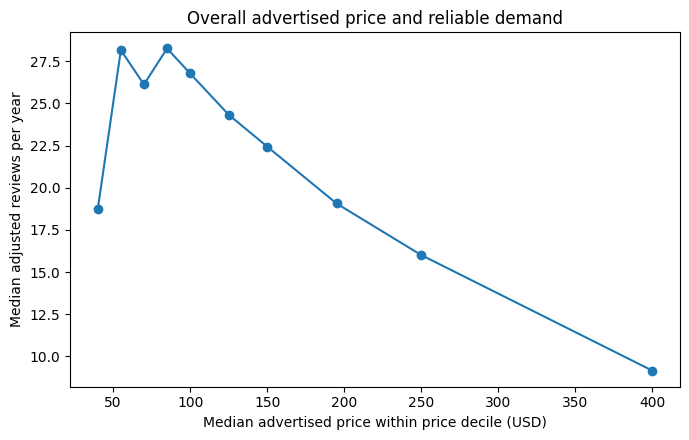

In [7]:
overall_rho, overall_p = spearmanr(
    demand_df["price"],
    demand_df["demand_rate_winsor"],
)

print(f"Overall Spearman rho: {overall_rho:.3f}")
print(f"Observations: {len(demand_df):,}")

demand_df["overall_price_band"] = pd.qcut(
    demand_df["price"].rank(method="first"),
    q=10,
    labels=[f"D{i}" for i in range(1, 11)],
)

overall_curve = (
    demand_df
    .groupby("overall_price_band", observed=True)
    .agg(
        listings=("id", "size"),
        median_price=("price", "median"),
        median_demand=("demand_rate_winsor", "median"),
    )
    .reset_index()
)

display(overall_curve.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    overall_curve["median_price"],
    overall_curve["median_demand"],
    marker="o",
)
ax.set_title("Overall advertised price and reliable demand")
ax.set_xlabel("Median advertised price within price decile (USD)")
ax.set_ylabel("Median adjusted reviews per year")
plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "overall_price_demand_curve.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 8. Price-demand relationship within each segment

The within-segment analysis measures the association between advertised price and reliable demand separately for each market segment. A more negative Spearman correlation indicates that higher-priced listings tend to have lower demand within that segment.

In [8]:
correlation_rows = []

for (cluster, segment), group in demand_df.groupby(
    ["cluster", "segment"]
):
    rho, p_value = spearmanr(
        group["price"],
        group["demand_rate_winsor"],
    )

    correlation_rows.append(
        {
            "cluster": cluster,
            "segment": segment,
            "reliable_demand_n": len(group),
            "median_price": group["price"].median(),
            "median_demand": group["demand_rate_winsor"].median(),
            "spearman_rho": rho,
            "spearman_p_value": p_value,
        }
    )

segment_correlations = (
    pd.DataFrame(correlation_rows)
    .sort_values("spearman_rho")
    .reset_index(drop=True)
)

display(segment_correlations.round(3))

,cluster,segment,reliable_demand_n,median_price,median_demand,spearman_rho,spearman_p_value
0,4,Less-central entire homes,4994,139.000,33.205,-0.131,0.000
1,0,Outer private rooms,2389,73.000,24.470,-0.102,0.000
2,3,Less-central private rooms,5987,60.000,22.450,-0.071,0.000
3,1,Central entire homes,7954,200.000,13.050,-0.057,0.000
4,2,Central private rooms,4851,91.000,22.260,-0.034,0.017


## 9. Segment-specific price bands

Each segment is divided into four equally sized price groups. Using segment-specific quartiles avoids comparing a private-room price directly with an entire-home price and shows how demand changes from the lower to the upper end of each segment's own price distribution.

In [9]:
band_labels = [
    "Q1 lower price",
    "Q2",
    "Q3",
    "Q4 higher price",
]

band_frames = []

for (cluster, segment), group in demand_df.groupby(
    ["cluster", "segment"]
):
    group = group.copy()

    group["segment_price_band"] = pd.qcut(
        group["price"].rank(method="first"),
        q=PRICE_BANDS,
        labels=band_labels,
    )

    band_frames.append(group)

demand_banded = pd.concat(
    band_frames,
    ignore_index=True,
)

segment_price_bands = (
    demand_banded
    .groupby(
        ["cluster", "segment", "segment_price_band"],
        observed=True,
    )
    .agg(
        listings=("id", "size"),
        median_price=("price", "median"),
        median_demand=("demand_rate_winsor", "median"),
    )
    .reset_index()
)

display(segment_price_bands.round(2))

,cluster,segment,segment_price_band,listings,median_price,median_demand
0,0,Outer private rooms,Q1 lower price,598,40.000,26.800
1,0,Outer private rooms,Q2,597,60.000,27.570
2,0,Outer private rooms,Q3,597,85.000,26.280
3,0,Outer private rooms,Q4 higher price,597,150.000,17.470
4,1,Central entire homes,Q1 lower price,1989,125.000,10.950
5,1,Central entire homes,Q2,1988,180.000,15.180
6,1,Central entire homes,Q3,1988,240.000,13.790
7,1,Central entire homes,Q4 higher price,1989,399.000,12.370
8,2,Central private rooms,Q1 lower price,1213,55.000,14.560
9,2,Central private rooms,Q2,1213,80.000,30.450


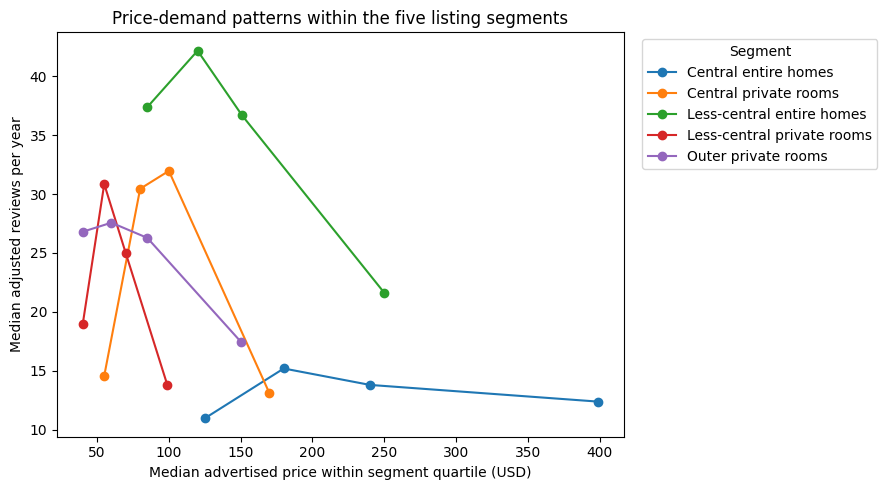

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

for segment, group in segment_price_bands.groupby("segment"):
    group = group.sort_values("median_price")
    ax.plot(
        group["median_price"],
        group["median_demand"],
        marker="o",
        label=segment,
    )

ax.set_title("Price-demand patterns within the five listing segments")
ax.set_xlabel("Median advertised price within segment quartile (USD)")
ax.set_ylabel("Median adjusted reviews per year")
ax.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "segment_price_demand_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 10. Adjusted within-segment price association

A separate regression is estimated within each segment using log-transformed price and demand.

The model adjusts for remaining differences in minimum stay, host listing count, distance from the city centre, room type and borough. Availability and review variables are not used as controls because they are directly involved in the construction or interpretation of the demand proxy.

The price coefficient is used to compare the direction and relative strength of the price-demand relationship across segments. It is an observational association rather than a causal elasticity.

In [11]:
model_rows = []

for (cluster, segment), group in demand_df.groupby(
    ["cluster", "segment"]
):
    model_data = group[
        [
            "demand_rate_winsor",
            "price",
            "minimum_nights",
            "calculated_host_listings_count",
            "dist_center_km",
            "room_type",
            "neighbourhood_group",
        ]
    ].dropna().copy()

    model_data["log_demand"] = np.log1p(
        model_data["demand_rate_winsor"]
    )
    model_data["log_price"] = np.log(
        model_data["price"]
    )
    model_data["log_minimum_nights"] = np.log1p(
        model_data["minimum_nights"]
    )
    model_data["log_host_listings"] = np.log1p(
        model_data["calculated_host_listings_count"]
    )

    model = smf.ols(
        (
            "log_demand ~ log_price "
            "+ log_minimum_nights "
            "+ log_host_listings "
            "+ dist_center_km "
            "+ C(room_type) "
            "+ C(neighbourhood_group)"
        ),
        data=model_data,
    ).fit(cov_type="HC3")

    lower_ci, upper_ci = model.conf_int().loc["log_price"]

    model_rows.append(
        {
            "cluster": cluster,
            "segment": segment,
            "n": int(model.nobs),
            "adjusted_log_price_coefficient": model.params["log_price"],
            "coefficient_ci_lower": lower_ci,
            "coefficient_ci_upper": upper_ci,
            "model_r2": model.rsquared,
        }
    )

segment_price_models = (
    pd.DataFrame(model_rows)
    .sort_values("adjusted_log_price_coefficient")
    .reset_index(drop=True)
)

display(segment_price_models.round(3))

,cluster,segment,n,adjusted_log_price_coefficient,coefficient_ci_lower,coefficient_ci_upper,model_r2
0,0,Outer private rooms,2389,-1.039,-1.160,-0.917,0.216
1,2,Central private rooms,4851,-0.838,-0.939,-0.737,0.203
2,3,Less-central private rooms,5987,-0.813,-0.924,-0.701,0.182
3,4,Less-central entire homes,4994,-0.742,-0.826,-0.657,0.214
4,1,Central entire homes,7954,-0.481,-0.545,-0.417,0.375


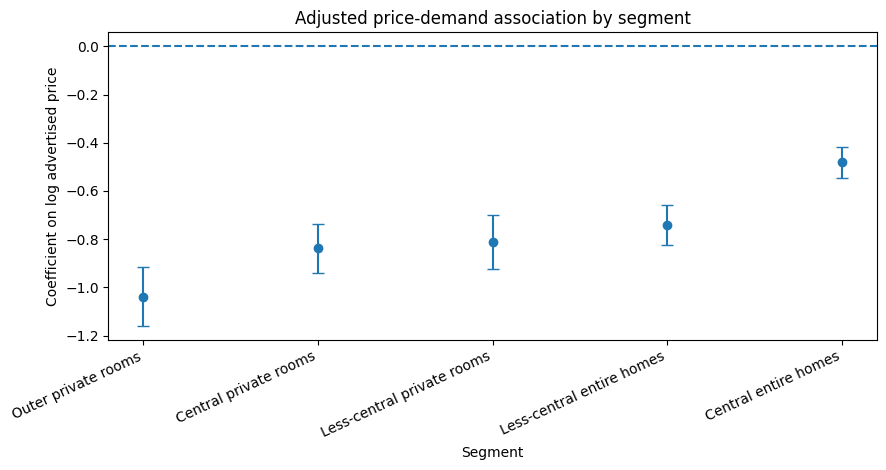

In [12]:
plot_models = (
    segment_price_models
    .sort_values("adjusted_log_price_coefficient")
    .reset_index(drop=True)
)

x = np.arange(len(plot_models))
coefs = plot_models["adjusted_log_price_coefficient"].to_numpy()
lower = plot_models["coefficient_ci_lower"].to_numpy()
upper = plot_models["coefficient_ci_upper"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.errorbar(
    x,
    coefs,
    yerr=np.vstack([coefs - lower, upper - coefs]),
    fmt="o",
    capsize=4,
)

ax.axhline(0, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_models["segment"],
    rotation=25,
    ha="right",
)
ax.set_title("Adjusted price-demand association by segment")
ax.set_ylabel("Coefficient on log advertised price")
ax.set_xlabel("Segment")

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "adjusted_price_association_by_segment.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 11. High-price demand retention

The demand level in the highest price quartile is compared with the lowest price quartile within each segment. A higher ratio indicates that demand is retained more strongly among the relatively expensive listings in that segment.

In [13]:
band_pivot = (
    segment_price_bands
    .pivot_table(
        index=["cluster", "segment"],
        columns="segment_price_band",
        values="median_demand",
        observed=True,
    )
    .reset_index()
)

band_pivot["high_price_demand_retention"] = (
    band_pivot["Q4 higher price"]
    / band_pivot["Q1 lower price"].replace(0, np.nan)
)

retention_table = band_pivot[
    [
        "cluster",
        "segment",
        "Q1 lower price",
        "Q4 higher price",
        "high_price_demand_retention",
    ]
].copy()

display(
    retention_table
    .sort_values("high_price_demand_retention", ascending=False)
    .round(3)
)

segment_price_band,cluster,segment,Q1 lower price,Q4 higher price,high_price_demand_retention
1,1,Central entire homes,10.950,12.370,1.130
2,2,Central private rooms,14.560,13.090,0.899
3,3,Less-central private rooms,18.930,13.760,0.727
0,0,Outer private rooms,26.800,17.470,0.652
4,4,Less-central entire homes,37.390,21.610,0.578


## 12. Pricing opportunity signals

The final comparison keeps the main pieces of evidence separate rather than combining them into a single weighted score.

Three signals are highlighted:

- **Demand opportunity** identifies the segment with the highest median reliable demand.
- **Price resilience** identifies the segment with the least negative adjusted price-demand coefficient.
- **Price sensitivity** identifies the segment with the most negative adjusted price-demand coefficient.

High-price demand retention is reported alongside these measures as supporting evidence. These signals indicate where further pricing investigation may be most useful; they do not estimate an optimal price.

In [14]:
segment_evidence_summary = (
    segment_summary[
        [
            "cluster",
            "segment",
            "listings",
            "median_price",
            "median_demand",
        ]
    ]
    .merge(
        segment_correlations[
            [
                "cluster",
                "spearman_rho",
            ]
        ],
        on="cluster",
        how="left",
    )
    .merge(
        segment_price_models[
            [
                "cluster",
                "adjusted_log_price_coefficient",
                "coefficient_ci_lower",
                "coefficient_ci_upper",
            ]
        ],
        on="cluster",
        how="left",
    )
    .merge(
        retention_table[
            [
                "cluster",
                "high_price_demand_retention",
            ]
        ],
        on="cluster",
        how="left",
    )
    .sort_values("median_demand", ascending=False)
    .reset_index(drop=True)
)

highest_demand = segment_evidence_summary.loc[
    segment_evidence_summary["median_demand"].idxmax()
]

most_price_resilient = segment_evidence_summary.loc[
    segment_evidence_summary["adjusted_log_price_coefficient"].idxmax()
]

most_price_sensitive = segment_evidence_summary.loc[
    segment_evidence_summary["adjusted_log_price_coefficient"].idxmin()
]

key_pricing_signals = pd.DataFrame(
    [
        {
            "signal": "Strongest demand opportunity",
            "segment": highest_demand["segment"],
            "median_price": highest_demand["median_price"],
            "median_demand": highest_demand["median_demand"],
            "adjusted_log_price_coefficient": highest_demand[
                "adjusted_log_price_coefficient"
            ],
            "high_price_demand_retention": highest_demand[
                "high_price_demand_retention"
            ],
        },
        {
            "signal": "Strongest price resilience",
            "segment": most_price_resilient["segment"],
            "median_price": most_price_resilient["median_price"],
            "median_demand": most_price_resilient["median_demand"],
            "adjusted_log_price_coefficient": most_price_resilient[
                "adjusted_log_price_coefficient"
            ],
            "high_price_demand_retention": most_price_resilient[
                "high_price_demand_retention"
            ],
        },
        {
            "signal": "Most price-sensitive segment",
            "segment": most_price_sensitive["segment"],
            "median_price": most_price_sensitive["median_price"],
            "median_demand": most_price_sensitive["median_demand"],
            "adjusted_log_price_coefficient": most_price_sensitive[
                "adjusted_log_price_coefficient"
            ],
            "high_price_demand_retention": most_price_sensitive[
                "high_price_demand_retention"
            ],
        },
    ]
)

print("Segment evidence summary")
display(
    segment_evidence_summary[
        [
            "segment",
            "median_price",
            "median_demand",
            "spearman_rho",
            "adjusted_log_price_coefficient",
            "high_price_demand_retention",
        ]
    ].round(3)
)

print("Key pricing signals")
display(key_pricing_signals.round(3))

Segment evidence summary


,segment,median_price,median_demand,spearman_rho,adjusted_log_price_coefficient,high_price_demand_retention
0,Less-central entire homes,135.000,33.205,-0.131,-0.742,0.578
1,Outer private rooms,72.000,24.470,-0.102,-1.039,0.652
2,Less-central private rooms,60.000,22.450,-0.071,-0.813,0.727
3,Central private rooms,90.000,22.260,-0.034,-0.838,0.899
4,Central entire homes,199.000,13.050,-0.057,-0.481,1.130


Key pricing signals


,signal,segment,median_price,median_demand,adjusted_log_price_coefficient,high_price_demand_retention
0,Strongest demand opportunity,Less-central entire homes,135.000,33.205,-0.742,0.578
1,Strongest price resilience,Central entire homes,199.000,13.050,-0.481,1.130
2,Most price-sensitive segment,Outer private rooms,72.000,24.470,-1.039,0.652


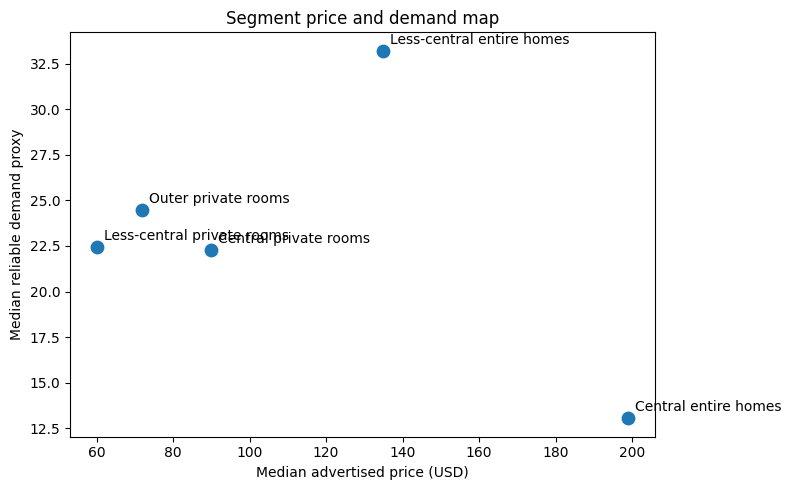

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    segment_evidence_summary["median_price"],
    segment_evidence_summary["median_demand"],
    s=80,
)

for _, row in segment_evidence_summary.iterrows():
    ax.annotate(
        row["segment"],
        (
            row["median_price"],
            row["median_demand"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_title("Segment price and demand map")
ax.set_xlabel("Median advertised price (USD)")
ax.set_ylabel("Median reliable demand proxy")

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "segment_price_demand_map.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 13. Main findings

The final outputs distinguish between demand opportunity, price resilience and price sensitivity rather than forcing the segments into a single ranking.

In [16]:
print("SEGMENT PRICE-DEMAND SUMMARY")
print("----------------------------")
print(f"Overall Spearman rho: {overall_rho:.3f}")
print(
    f"Strongest demand opportunity: "
    f"{highest_demand['segment']} "
    f"(median demand {highest_demand['median_demand']:.2f})"
)
print(
    f"Strongest price resilience: "
    f"{most_price_resilient['segment']} "
    f"(adjusted coefficient "
    f"{most_price_resilient['adjusted_log_price_coefficient']:.3f})"
)
print(
    f"Most price-sensitive segment: "
    f"{most_price_sensitive['segment']} "
    f"(adjusted coefficient "
    f"{most_price_sensitive['adjusted_log_price_coefficient']:.3f})"
)

SEGMENT PRICE-DEMAND SUMMARY
----------------------------
Overall Spearman rho: -0.117
Strongest demand opportunity: Less-central entire homes (median demand 33.20)
Strongest price resilience: Central entire homes (adjusted coefficient -0.481)
Most price-sensitive segment: Outer private rooms (adjusted coefficient -1.039)


## 14. Interpretation limits

The demand measure is based on review activity rather than observed bookings. Availability records how many days a host made the listing available and does not reveal whether unavailable dates were booked or blocked.

The data is cross-sectional and advertised price is not a transaction price. Differences between price and demand can also reflect unobserved listing characteristics, local market conditions and host behaviour.

The results therefore identify segments with stronger or weaker pricing signals. They do not show that changing price would cause demand to change by the estimated amount, and they do not identify revenue-maximising prices.

## 15. Save results

In [17]:
segment_summary_path = OUTPUT_DIR / "segment_summary.csv"
correlations_path = OUTPUT_DIR / "segment_price_demand_correlations.csv"
bands_path = OUTPUT_DIR / "segment_price_bands.csv"
models_path = OUTPUT_DIR / "segment_price_models.csv"
evidence_path = OUTPUT_DIR / "segment_pricing_evidence.csv"
signals_path = OUTPUT_DIR / "key_pricing_signals.csv"

segment_summary.to_csv(segment_summary_path, index=False)
segment_correlations.to_csv(correlations_path, index=False)
segment_price_bands.to_csv(bands_path, index=False)
segment_price_models.to_csv(models_path, index=False)
segment_evidence_summary.to_csv(evidence_path, index=False)
key_pricing_signals.to_csv(signals_path, index=False)

print(f"Saved segment summary: {segment_summary_path}")
print(f"Saved correlations: {correlations_path}")
print(f"Saved price bands: {bands_path}")
print(f"Saved segment models: {models_path}")
print(f"Saved evidence summary: {evidence_path}")
print(f"Saved key pricing signals: {signals_path}")
print(f"Saved figures: {FIGURE_DIR}")

Saved segment summary: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\segment_summary.csv
Saved correlations: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\segment_price_demand_correlations.csv
Saved price bands: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\segment_price_bands.csv
Saved segment models: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\segment_price_models.csv
Saved evidence summary: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\segment_pricing_evidence.csv
Saved key pricing signals: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\key_pricing_signals.csv
Saved figures: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\segment_analysis\figu